# 01. Eksplorasi data (EDA)

Notebook ini hanya memanggil fungsi dari `src/` (`load_raw`, `clean`, `chronological_split`, `describe_splits`); tidak ada logika pembersihan atau pembagian data yang ditulis ulang di sini. Tujuannya melihat data sebelum eksperimen: ukuran, kualitas, kronologi, dan pembagian latih/validasi/uji.

Kelas positif: `No-show = Yes`.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve().parent          # notebook dijalankan dari folder notebooks/
sys.path.insert(0, str(ROOT / "src"))
DATA = ROOT / "data" / "KaggleV2-May-2016.csv"
if not DATA.exists():
    raise FileNotFoundError(f"Taruh CSV Kaggle di {DATA} (lihat data/README.md).")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

In [2]:
from preprocessing import load_raw, clean, chronological_split
from run_experiments import describe_splits
%matplotlib inline

raw = load_raw(str(DATA))
print("Baris mentah:", len(raw), "| kolom:", raw.shape[1])
print("\nNilai hilang per kolom:\n", raw.isna().sum().to_string())
print("\nNilai Handcap:", sorted(int(v) for v in raw["handicap"].unique()))
print("Usia min/maks:", raw["age"].min(), raw["age"].max())
print("Jumlah lingkungan:", raw["neighbourhood"].nunique())
raw.dtypes.to_frame("dtype")  # baris data tidak ditampilkan agar data Kaggle tidak ikut tersimpan di repo

Baris mentah: 110527 | kolom: 14

Nilai hilang per kolom:
 patient_id         0
appointment_id     0
gender             0
scheduled_day      0
appointment_day    0
age                0
neighbourhood      0
scholarship        0
hypertension       0
diabetes           0
alcoholism         0
handicap           0
sms_received       0
no_show            0

Nilai Handcap: [0, 1, 2, 3, 4]
Usia min/maks: -1 115
Jumlah lingkungan: 81


,dtype
patient_id,float64
appointment_id,int64
gender,str
scheduled_day,str
appointment_day,str
age,int64
neighbourhood,str
scholarship,int64
hypertension,int64
diabetes,int64


In [3]:
df, report = clean(raw)
import json
print(json.dumps(report, indent=2, default=str))

{
  "rows_raw": 110527,
  "dropped_duplicate_appointment_id": 0,
  "dropped_negative_lead_days": 5,
  "dropped_invalid_age": 1,
  "rows_clean": 110521,
  "no_show_rate_clean": 0.2018982817745044,
  "unique_patients": 62298,
  "rows_with_repeated_patient": 72601,
  "appointment_day_min": "2016-04-29",
  "appointment_day_max": "2016-06-08",
  "dates_without_appointments": [
    "2016-04-30 (Saturday)",
    "2016-05-01 (Sunday)",
    "2016-05-07 (Saturday)",
    "2016-05-08 (Sunday)",
    "2016-05-15 (Sunday)",
    "2016-05-21 (Saturday)",
    "2016-05-22 (Sunday)",
    "2016-05-23 (Monday)",
    "2016-05-26 (Thursday)",
    "2016-05-27 (Friday)",
    "2016-05-28 (Saturday)",
    "2016-05-29 (Sunday)",
    "2016-06-04 (Saturday)",
    "2016-06-05 (Sunday)"
  ]
}


## Proporsi no-show

Proporsi keseluruhan dan menurut beberapa kelompok. Ini deskripsi, bukan analisis sebab.

In [4]:
print(f"No-show keseluruhan: {df['target'].mean():.4f}")
df["lead_bin"] = pd.cut(df["lead_days"], [-1, 0, 3, 7, 14, 30, 200], labels=["0", "1-3", "4-7", "8-14", "15-30", ">30"])
print("\nMenurut jarak hari penjadwalan (lead_days):")
print(df.groupby("lead_bin", observed=True)["target"].agg(["mean", "size"]).round(4).to_string())
print("\nMenurut SMS_received (observasional, bukan efek kausal):")
print(df.groupby("sms_received")["target"].agg(["mean", "size"]).round(4).to_string())

No-show keseluruhan: 0.2019

Menurut jarak hari penjadwalan (lead_days):
            mean   size
lead_bin               
0         0.0465  38562
1-3       0.2289  14675
4-7       0.2520  17510
8-14      0.3047  12025
15-30     0.3259  17371
>30       0.3300  10378

Menurut SMS_received (observasional, bukan efek kausal):
                mean   size
sms_received               
0             0.1670  75039
1             0.2757  35482


## Pembagian kronologis 60/20/20

Semua baris pada satu tanggal janji berada di satu bagian.

In [5]:
train, val, test = chronological_split(df)
split_table = describe_splits(train, val, test, val, test)
split_table

,split,n_rows,start_date,end_date,no_show_rate,n_patients,pct_rows_patient_seen_in_earlier_split
0,train,67360,2016-04-29,2016-05-20,0.2109,44253,0.00
1,validation,21175,2016-05-24,2016-06-01,0.1906,17246,49.93
2,test,21986,2016-06-02,2016-06-08,0.1851,18212,55.47


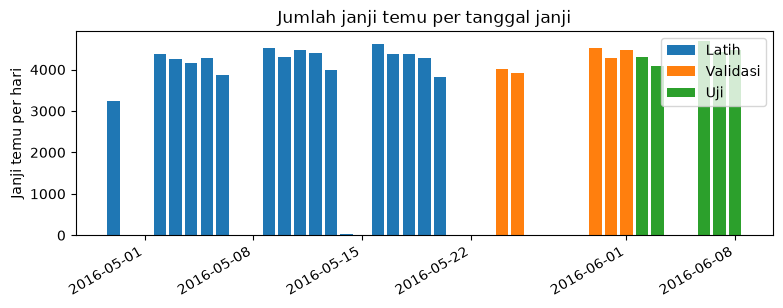

Tanggal tanpa janji temu dalam rentang: ['2016-04-30 (Saturday)', '2016-05-01 (Sunday)', '2016-05-07 (Saturday)', '2016-05-08 (Sunday)', '2016-05-15 (Sunday)', '2016-05-21 (Saturday)', '2016-05-22 (Sunday)', '2016-05-23 (Monday)', '2016-05-26 (Thursday)', '2016-05-27 (Friday)', '2016-05-28 (Saturday)', '2016-05-29 (Sunday)', '2016-06-04 (Saturday)', '2016-06-05 (Sunday)']


In [6]:
daily = df.groupby(df["appointment_day"].dt.normalize()).size()
fig, ax = plt.subplots(figsize=(9, 3))
colors = {}
for name, part, c in [("Latih", train, "tab:blue"), ("Validasi", val, "tab:orange"), ("Uji", test, "tab:green")]:
    d = daily[daily.index.isin(part["appointment_day"].dt.normalize())]
    ax.bar(d.index, d.values, color=c, label=name, width=0.8)
ax.set(ylabel="Janji temu per hari", title="Jumlah janji temu per tanggal janji")
ax.legend()
fig.autofmt_xdate()
plt.show()
print("Tanggal tanpa janji temu dalam rentang:", report["dates_without_appointments"])